# Proyecto 3 — Mejorando algoritmos con CUDA
**CC3069 Computación Paralela y Distribuida · UVG · Semestre II 2026**

Algoritmo a acelerar: *Laboratorio 3 de Data Science — Reconocimiento de Lenguaje de Señas ASL* (dataset ASL Alphabet de Kaggle, 29 clases, CNN en Keras).

Integrantes: Roberto Nájera, Genser Catalán, Estuardo Castro

**Cómo usar este notebook (Google Colab):** `Entorno de ejecución → Cambiar tipo de entorno → GPU (T4)` y luego `Ejecutar todo`.
Las celdas están separadas por fase para cumplir con el entregable (preparación de datos en CPU ≠ entrenamiento en GPU).
Al final se genera `results/` (CSV, gráficas, logs de `nvidia-smi`) y un `.zip` para descargar.

| Fase | Secuencial (línea base) | Paralelo (propuesta) |
|---|---|---|
| **A. Preparación de imágenes** (leer JPEG, resize, normalizar) | 1 proceso, un `for` sobre las imágenes | `N` procesos en los núcleos del **CPU** |
| **B. Entrenamiento de la CNN** | TensorFlow en **CPU** | TensorFlow sobre **CUDA/cuDNN** en **GPU** |
| **C. Inferencia (test)** | CPU | GPU |

## 0. Setup y verificación del hardware

In [1]:
# En Colab ya vienen instalados TensorFlow, numpy, pandas, scikit-learn, Pillow, psutil y numba.
# kagglehub se usa para bajar el dataset (igual que en el Lab 3).
!pip install -q kagglehub tabulate

In [2]:
import os, sys, time, math, json, random, shutil, subprocess, threading, platform, zipfile
from pathlib import Path
from contextlib import contextmanager

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# ---------------- Configuración del experimento ----------------
IMG_SIZE      = 64      # igual que el Lab 3
N_PER_CLASS   = 700     # igual que el Lab 3 (submuestra por clase)
BATCH_SIZE    = 32      # igual que el Lab 3
LEARNING_RATE = 0.0005  # CNN 2 (mejor modelo del Lab 3)
EPOCHS_BENCH  = 4       # épocas FIJAS (sin early stopping) para que CPU y GPU hagan el mismo trabajo
REPEATS       = 3       # repeticiones de cada medición (se reporta promedio ± desv. estándar)
# Si el CPU de Colab tarda demasiado, baje EPOCHS_BENCH a 3; tiene que ser igual en CPU y GPU.

RESULTS_DIR = Path("results"); RESULTS_DIR.mkdir(exist_ok=True)

N_CPU = len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else os.cpu_count()
GPUS  = tf.config.list_physical_devices("GPU")
GPU_DEVICE = "/GPU:0" if GPUS else None

print("Python      :", sys.version.split()[0], "|", platform.platform())
print("TensorFlow  :", tf.__version__, "| Keras:", keras.__version__)
print("Núcleos CPU :", N_CPU, "| RAM total: %.1f GB" % (psutil.virtual_memory().total / 1e9))
print("GPUs        :", GPUS)
if not GPUS:
    print("\n⚠️  No hay GPU. Cambie el entorno de ejecución a GPU; sin eso solo se mide la parte CPU.")

Python      : 3.13.16 | Linux-6.6.159+-x86_64-with-glibc2.39
TensorFlow  : 2.21.0 | Keras: 3.13.2
Núcleos CPU : 2 | RAM total: 13.6 GB
GPUs        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
# Evidencia de que el entorno reconoce el hardware (captura/ log para el informe)
hw = subprocess.run("nvidia-smi; echo; lscpu | head -20", shell=True, capture_output=True, text=True).stdout
print(hw)
(RESULTS_DIR / "hardware.txt").write_text(hw)
if GPUS:
    print(tf.sysconfig.get_build_info().get("cuda_version"), "← CUDA con el que se compiló TF |",
          tf.sysconfig.get_build_info().get("cudnn_version"), "← cuDNN")

Sat Nov 14 04:53:30 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### Monitor de recursos (evidencia de uso de CPU y GPU)
Un hilo en segundo plano muestrea cada 1 s: **uso de cada núcleo del CPU** (`psutil`), **utilización y memoria del GPU** (`nvidia-smi --query-gpu`) y RAM.
Cada fase se ejecuta dentro de `monitored("nombre")`, que guarda el CSV y la gráfica en `results/`.
Estas gráficas son la evidencia de ejecución; además deben tomarse capturas de pantalla de `!nvidia-smi` y del administrador de recursos de Colab (panel derecho → *Recursos*) mientras corre cada fase.

> El monitor corre igual en todas las fases (CPU y GPU), así que su costo mínimo afecta por igual a las dos versiones.

In [4]:
def _gpu_query():
    try:
        out = subprocess.check_output(
            ["nvidia-smi", "--query-gpu=utilization.gpu,memory.used,memory.total",
             "--format=csv,noheader,nounits"], text=True, timeout=5).strip().split("\n")[0]
        u, m, t = [float(v) for v in out.split(",")]
        return u, m, t
    except Exception:
        return np.nan, np.nan, np.nan


class ResourceMonitor:
    def __init__(self, interval=1.0):
        self.interval, self._stop, self._rows, self._thread = interval, threading.Event(), [], None

    def _loop(self):
        psutil.cpu_percent(percpu=True)            # "cebar" el contador
        t0 = time.perf_counter()
        while not self._stop.is_set():
            per_core = psutil.cpu_percent(interval=self.interval, percpu=True)   # bloquea 1 s
            u, m, t = _gpu_query()
            row = {"t": time.perf_counter() - t0, "cpu_mean": float(np.mean(per_core)),
                   "gpu_util": u, "gpu_mem_used_mb": m, "gpu_mem_total_mb": t,
                   "ram_used_gb": psutil.virtual_memory().used / 1e9}
            row.update({f"cpu{i}": c for i, c in enumerate(per_core)})
            self._rows.append(row)

    def start(self):
        self._thread = threading.Thread(target=self._loop, daemon=True); self._thread.start()

    def stop(self):
        self._stop.set(); self._thread.join()
        return pd.DataFrame(self._rows)


def plot_monitor(df, title, path):
    cores = [c for c in df.columns if c.startswith("cpu") and c != "cpu_mean"]
    fig, ax = plt.subplots(1, 3, figsize=(17, 3.8))
    for c in cores:
        ax[0].plot(df["t"], df[c], lw=1, label=c)
    ax[0].plot(df["t"], df["cpu_mean"], "k--", lw=1.5, label="promedio")
    ax[0].set(title="CPU: uso por núcleo (%)", xlabel="s", ylim=(0, 105)); ax[0].legend(fontsize=7, ncol=2)
    ax[1].plot(df["t"], df["gpu_util"], color="tab:green")
    ax[1].set(title="GPU: utilización (%)", xlabel="s", ylim=(0, 105))
    ax[2].plot(df["t"], df["gpu_mem_used_mb"], color="tab:red")
    ax[2].set(title="GPU: memoria usada (MB)", xlabel="s")
    fig.suptitle(title); plt.tight_layout(); plt.savefig(path, dpi=130); plt.show()


MONITOR = {}

@contextmanager
def monitored(label):
    mon = ResourceMonitor(); mon.start()
    try:
        yield
    finally:
        df = mon.stop(); MONITOR[label] = df
        df.to_csv(RESULTS_DIR / f"uso_{label}.csv", index=False)
        if len(df): plot_monitor(df, label, RESULTS_DIR / f"uso_{label}.png")

## 1. Análisis de la solución secuencial existente (Paso 1)

Código del Lab 3 revisado: `src/dataset.py`, `src/preprocessing.py` y `notebooks/02_modelos_cnn.ipynb` (CNN 1, CNN 2 y red fully-connected). El modelo que se acelera es la **CNN 2** (mejor del Lab 3: 95.70 % accuracy en test) con el mismo preprocesamiento.

### Tabla 1 — Operaciones identificadas, desde las imágenes hasta el resultado

| No. | Operación identificada | Descripción de su funcionamiento | Dónde corre |
|---|---|---|---|
| 1 | Obtención del dataset (`ensure_dataset`) | Verifica que estén las 29 carpetas de clase; si faltan, descarga con `kagglehub` (~87 000 JPG de 200×200) y copia las clases faltantes. | CPU / disco / red |
| 2 | Manifiesto y submuestra (`build_manifest`) | Recorre cada clase y toma 700 rutas al azar (semilla 42) → DataFrame `[filepath, label]` de 20 300 filas. No toca píxeles. | CPU |
| 3 | Split estratificado (`stratified_split`) | Divide las rutas 70/15/15 manteniendo la proporción por clase: 14 210 / 3 045 / 3 045. | CPU |
| 4 | Lectura y decodificación (`Image.open`) | Lee el JPG del disco y lo decodifica (Huffman + IDCT) a un arreglo 200×200×3. | CPU / disco |
| 5 | Conversión a RGB y *resize* (`convert("RGB").resize`) | Reduce 200×200 → 64×64 (filtro por defecto de Pillow = bicúbico). | CPU |
| 6 | Normalización | `uint8 → float32` y división entre 255 → rango [0, 1]. Resultado: tensores `X` (N,64,64,3) e `y`. | CPU |
| 7 | Construcción de la CNN 2 (`build_cnn2`) | 3 bloques *Conv2D + BatchNorm + MaxPool* (32, 64, 128 filtros), `Dense(256)`, `Dense(128)`, softmax de 29 clases. | — |
| 8 | Entrenamiento (`model.fit`) | Por cada mini-batch de 32: propagación hacia adelante, entropía cruzada, retropropagación y paso de Adam. Evalúa validación al final de cada época. | **matemática densa** |
| 9 | Evaluación (`model.predict` + métricas) | Propagación hacia adelante sobre las 3 045 imágenes de test y cálculo de accuracy/precision/recall. | **matemática densa** |

### Tabla 2 — Operaciones repetitivas

| Operación repetitiva | Datos que procesa | Cantidad de repeticiones |
|---|---|---|
| Lectura + decodificación + resize + normalización (ops. 4-6) | 1 imagen JPG de 200×200×3 por iteración (independientes entre sí) | 20 300 (14 210 train + 3 045 val + 3 045 test) |
| Paso de entrenamiento (op. 8) | 1 mini-batch de 32 imágenes de 64×64×3 | ⌈14 210/32⌉ = 445 por época × épocas (hasta 15 en el Lab 3; `EPOCHS_BENCH` aquí) |
| Convolución 3×3 + BatchNorm + MaxPool (op. 8, 9) | Mapas de activación de todo el batch (32×62×62×32, 32×29×29×64, 32×12×12×128 …) | 3 capas × cada paso hacia adelante y hacia atrás |
| Multiplicación matriz×matriz de las capas densas (op. 8, 9) | Batch (32×4608) · pesos (4608×256), luego (32×256)·(256×128) | cada paso, adelante y atrás |
| Evaluación de validación (op. 8) | 3 045 imágenes en lotes de 32 | 96 lotes por época |
| Inferencia sobre test (op. 9) | 3 045 imágenes | 1 vez (96 lotes de 32) |

**Observación sobre el código original:** el comentario de `load_and_preprocess` dice "interpolación bilineal", pero `Image.resize` sin argumento usa **bicúbico** en Pillow ≥ 7. No afecta nada de este proyecto porque la versión paralela usa exactamente la misma llamada.

## 2. Código original secuencial (Lab 3)
Se copia el código tal cual del Lab 3 (`dataset.py`, `preprocessing.py`, `build_cnn2` de `02_modelos_cnn.ipynb`). Cambios mínimos, marcados con `# [PROY3]`: (a) login de Kaggle si hace falta, (b) `sorted()` al listar archivos para que la submuestra sea reproducible entre ejecuciones.

In [5]:
# ======================= CÓDIGO ORIGINAL (Lab 3) — dataset.py =======================
KAGGLE_DATASET = "grassknoted/asl-alphabet"
RAW_DIR = Path("data/asl_alphabet_train/asl_alphabet_train")
EXPECTED_CLASSES = frozenset([chr(c) for c in range(ord("A"), ord("Z") + 1)] + ["del", "nothing", "space"])

def _populated_classes(raw_dir):
    if not raw_dir.is_dir():
        return set()
    return {d.name for d in raw_dir.iterdir() if d.is_dir() and next(d.glob("*.jpg"), None) is not None}

def _find_class_root(download_path):
    candidates = [download_path] + [d for d in download_path.rglob("*") if d.is_dir()]
    for candidate in candidates:
        if EXPECTED_CLASSES <= _populated_classes(candidate):
            return candidate
    raise RuntimeError(f"No se encontraron las {len(EXPECTED_CLASSES)} clases dentro de {download_path}.")

def ensure_dataset(raw_dir=RAW_DIR):
    missing = EXPECTED_CLASSES - _populated_classes(raw_dir)
    if not missing:
        print(f"Dataset completo en {raw_dir} ({len(EXPECTED_CLASSES)} clases), no se descarga nada.")
        return raw_dir
    print(f"Faltan {len(missing)} clases en {raw_dir}. Descargando de Kaggle...")
    import kagglehub
    try:
        download_path = Path(kagglehub.dataset_download(KAGGLE_DATASET))
    except Exception as e:                       # [PROY3] en Colab a veces pide credenciales
        print("Descarga anónima falló (", type(e).__name__, "). Iniciando sesión en Kaggle...")
        kagglehub.login()
        download_path = Path(kagglehub.dataset_download(KAGGLE_DATASET))
    class_root = _find_class_root(download_path)
    raw_dir.mkdir(parents=True, exist_ok=True)
    for name in sorted(missing):
        shutil.copytree(class_root / name, raw_dir / name, dirs_exist_ok=True)
    still_missing = EXPECTED_CLASSES - _populated_classes(raw_dir)
    if still_missing:
        raise RuntimeError(f"Dataset incompleto. Faltan: {sorted(still_missing)}")
    print(f"Dataset listo en {raw_dir}.")
    return raw_dir

# ================= CÓDIGO ORIGINAL (Lab 3) — preprocessing.py (SECUENCIAL) =================
def get_classes(raw_dir=RAW_DIR):
    ensure_dataset(raw_dir)
    return sorted([d.name for d in raw_dir.iterdir() if d.is_dir()])

def build_manifest(raw_dir=RAW_DIR, n_per_class=N_PER_CLASS, seed=SEED):
    ensure_dataset(raw_dir)
    rng = np.random.RandomState(seed)
    rows = []
    for class_dir in sorted(raw_dir.iterdir()):
        if not class_dir.is_dir():
            continue
        files = sorted(list(class_dir.glob("*.jpg")) + list(class_dir.glob("*.png")))   # [PROY3] sorted()
        if len(files) > n_per_class:
            idx = rng.choice(len(files), size=n_per_class, replace=False)
            files = [files[i] for i in idx]
        rows.extend({"filepath": str(f), "label": class_dir.name} for f in files)
    manifest = pd.DataFrame(rows)
    print(f"Manifiesto: {len(manifest)} imágenes, {manifest['label'].nunique()} clases")
    return manifest

def stratified_split(manifest, train_size=0.70, val_size=0.15, test_size=0.15, seed=SEED):
    train_df, temp_df = train_test_split(manifest, train_size=train_size, stratify=manifest["label"], random_state=seed)
    relative_val = val_size / (val_size + test_size)
    val_df, test_df = train_test_split(temp_df, train_size=relative_val, stratify=temp_df["label"], random_state=seed)
    print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
    return train_df.reset_index(drop=True), val_df.reset_index(drop=True), test_df.reset_index(drop=True)

def load_and_preprocess(df, img_size=IMG_SIZE, classes=None):
    """SECUENCIAL: una imagen a la vez, en un solo proceso."""
    if classes is None:
        classes = sorted(df["label"].unique())
    class_to_idx = {c: i for i, c in enumerate(classes)}
    X = np.zeros((len(df), img_size, img_size, 3), dtype=np.float32)
    y = np.zeros(len(df), dtype=np.int64)
    for i, row in enumerate(df.itertuples()):
        img = Image.open(row.filepath).convert("RGB").resize((img_size, img_size))
        X[i] = np.asarray(img, dtype=np.float32) / 255.0
        y[i] = class_to_idx[row.label]
    return X, y

# ================= CÓDIGO ORIGINAL (Lab 3) — CNN 2 de 02_modelos_cnn.ipynb =================
def build_cnn2(learning_rate=0.0005):
    model = keras.Sequential([
        layers.Input(shape=(64, 64, 3)),
        layers.Conv2D(32, kernel_size=(3, 3), activation="relu"), layers.BatchNormalization(), layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Conv2D(64, kernel_size=(3, 3), activation="relu"), layers.BatchNormalization(), layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Conv2D(128, kernel_size=(3, 3), activation="relu"), layers.BatchNormalization(), layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Flatten(),
        layers.Dense(256, activation="relu"), layers.Dropout(0.4),
        layers.Dense(128, activation="relu"), layers.Dropout(0.3),
        layers.Dense(29, activation="softmax"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

## 3. Medición del tiempo secuencial — Fase A: preparación de datos (Paso 2)

**Procedimiento (mismas condiciones para secuencial y paralelo):**
1. Se arma el manifiesto y el split **una sola vez** → exactamente las mismas 20 300 rutas en todas las mediciones.
2. *Lectura en frío:* se lee cada archivo una vez para que el sistema operativo los deje en caché. Así las `REPEATS` mediciones comparan **cómputo**, no la velocidad del disco de Colab (la primera lectura se reporta aparte).
3. Se repite `REPEATS` veces la carga completa (train + val + test) y se reporta promedio ± desviación estándar.

In [6]:
t0 = time.perf_counter()
classes  = get_classes()
manifest = build_manifest()
train_df, val_df, test_df = stratified_split(manifest)
all_paths = list(manifest["filepath"])
print(f"Setup de datos (descarga/manifiesto/split): {time.perf_counter()-t0:.1f} s")

# Lectura en frío (solo para calentar el caché de archivos)
t0 = time.perf_counter()
bytes_total = 0
for p in all_paths:
    with open(p, "rb") as f:
        bytes_total += len(f.read())
T_COLD_READ = time.perf_counter() - t0
print(f"Lectura en frío de {len(all_paths)} archivos ({bytes_total/1e6:.0f} MB): {T_COLD_READ:.1f} s")

Faltan 29 clases en data/asl_alphabet_train/asl_alphabet_train. Descargando de Kaggle...
Using Colab cache for faster access to the 'asl-alphabet' dataset.
Dataset listo en data/asl_alphabet_train/asl_alphabet_train.
Dataset completo en data/asl_alphabet_train/asl_alphabet_train (29 clases), no se descarga nada.
Manifiesto: 20300 imágenes, 29 clases
Train: 14210 | Val: 3045 | Test: 3045
Setup de datos (descarga/manifiesto/split): 1030.4 s
Lectura en frío de 20300 archivos (258 MB): 0.4 s


  secuencial, ejecución 1/3: 23.14 s
  secuencial, ejecución 2/3: 23.46 s
  secuencial, ejecución 3/3: 23.96 s


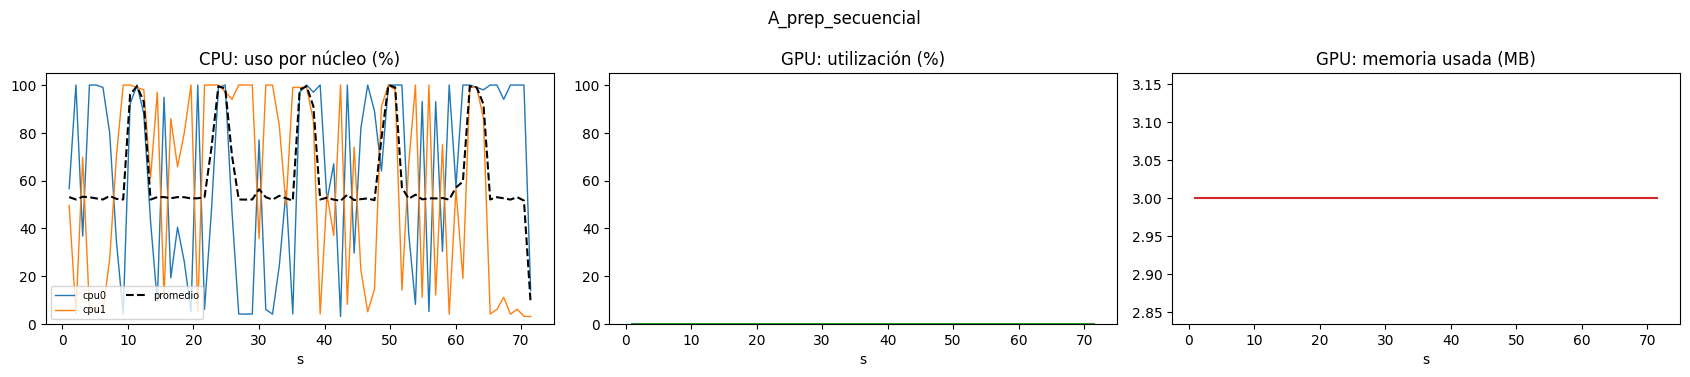

Preparación SECUENCIAL: 23.52 ± 0.34 s
Shapes: (14210, 64, 64, 3) (3045, 64, 64, 3) (3045, 64, 64, 3) | dtype float32


In [7]:
def prep_sequential(train_df, val_df, test_df, classes):
    """Flujo original: tres llamadas a load_and_preprocess, una imagen a la vez."""
    Xtr, ytr = load_and_preprocess(train_df, classes=classes)
    Xva, yva = load_and_preprocess(val_df,   classes=classes)
    Xte, yte = load_and_preprocess(test_df,  classes=classes)
    return Xtr, ytr, Xva, yva, Xte, yte

prep_seq_times = []
with monitored("A_prep_secuencial"):
    for r in range(REPEATS):
        t0 = time.perf_counter()
        data_seq = prep_sequential(train_df, val_df, test_df, classes)
        prep_seq_times.append(time.perf_counter() - t0)
        print(f"  secuencial, ejecución {r+1}/{REPEATS}: {prep_seq_times[-1]:.2f} s")
print(f"Preparación SECUENCIAL: {np.mean(prep_seq_times):.2f} ± {np.std(prep_seq_times):.2f} s")
Xtr, ytr, Xva, yva, Xte, yte = data_seq
print("Shapes:", Xtr.shape, Xva.shape, Xte.shape, "| dtype", Xtr.dtype)

### Medición secuencial — Fase B/C: entrenamiento e inferencia en **CPU**
Se entrena la CNN 2 del Lab 3 con `EPOCHS_BENCH` épocas **fijas** (sin `EarlyStopping`, para que CPU y GPU ejecuten exactamente la misma cantidad de trabajo), mismo `batch_size=32`, misma semilla y mismos datos. Se mide el tiempo total de `fit` (incluye validación en cada época), el tiempo por época y la inferencia sobre el conjunto de test.

Factores que influyen en el rendimiento del CPU: núcleos disponibles (Colab gratis ≈ 2 vCPU), vectorización AVX/oneDNN, tamaño de batch, *overhead* de Python/TF por paso, caché de archivos y ruido de otras VMs en el mismo host.

In [8]:
class EpochTimer(keras.callbacks.Callback):
    def __init__(self, snapshot_path=None):
        super().__init__(); self.snapshot_path = snapshot_path
    def on_train_begin(self, logs=None): self.times = []
    def on_epoch_begin(self, epoch, logs=None):
        self.t = time.perf_counter()
        if self.snapshot_path and epoch == 1:            # captura de nvidia-smi a media ejecución
            out = subprocess.run("nvidia-smi", capture_output=True, text=True).stdout
            Path(self.snapshot_path).write_text(out)
    def on_epoch_end(self, epoch, logs=None): self.times.append(time.perf_counter() - self.t)


def train_once(device, builder, data, epochs, batch_size, snapshot_path=None):
    """Entrena de cero y mide. Los numpy se pasan directo a fit(): en GPU esto INCLUYE las
    transferencias host→device de cada batch, como pide el enunciado."""
    Xtr, ytr, Xva, yva, Xte, yte = data
    keras.utils.set_random_seed(SEED)
    with tf.device(device):
        model = builder()
        timer = EpochTimer(snapshot_path)
        t0 = time.perf_counter()
        model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=epochs, batch_size=batch_size,
                  callbacks=[timer], verbose=0, shuffle=True)
        t_train = time.perf_counter() - t0
        t0 = time.perf_counter()
        prob = model.predict(Xte, batch_size=256, verbose=0)
        t_pred = time.perf_counter() - t0
    acc = accuracy_score(yte, prob.argmax(1))
    return {"train_s": t_train, "epoch_first_s": timer.times[0],
            "epoch_steady_s": float(np.mean(timer.times[1:])) if len(timer.times) > 1 else timer.times[0],
            "infer_s": t_pred, "test_acc": acc}


def warmup(device, builder, data, batch_size):
    """1 época sobre 1 024 imágenes, sin medir: inicializa cuDNN/oneDNN y traza el grafo."""
    Xtr, ytr, Xva, yva, Xte, yte = data
    small = (Xtr[:1024], ytr[:1024], Xva[:256], yva[:256], Xte[:256], yte[:256])
    train_once(device, builder, small, 1, batch_size)

runs = []   # una fila por ejecución de cada configuración

def benchmark(name, device, builder, data, batch_size, snapshot_path=None):
    warmup(device, builder, data, batch_size)
    for r in range(REPEATS):
        res = train_once(device, builder, data, EPOCHS_BENCH, batch_size,
                         snapshot_path if r == REPEATS - 1 else None)
        res.update(config=name, run=r + 1, batch_size=batch_size, epochs=EPOCHS_BENCH)
        runs.append(res)
        print(f"  {name} [{r+1}/{REPEATS}] fit={res['train_s']:.1f}s  época(estable)={res['epoch_steady_s']:.1f}s  "
              f"infer={res['infer_s']:.2f}s  acc_test={res['test_acc']:.4f}")

  CPU (secuencial, bs=32) [1/3] fit=649.1s  época(estable)=162.8s  infer=10.46s  acc_test=0.7179
  CPU (secuencial, bs=32) [2/3] fit=722.2s  época(estable)=185.0s  infer=6.84s  acc_test=0.7179
  CPU (secuencial, bs=32) [3/3] fit=705.3s  época(estable)=179.8s  infer=7.40s  acc_test=0.7179


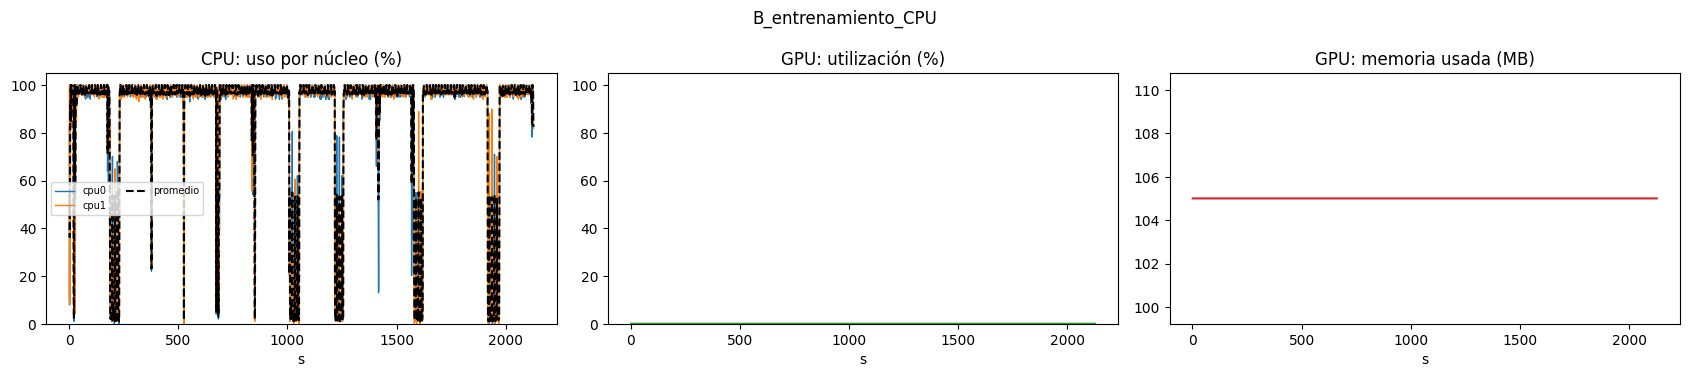

In [9]:
with monitored("B_entrenamiento_CPU"):
    benchmark("CPU (secuencial, bs=32)", "/CPU:0", lambda: build_cnn2(LEARNING_RATE), data_seq, BATCH_SIZE)

## 4. Identificación de oportunidades de paralelización (Paso 3)

| Operación | ¿Paralelizable? | ¿Dónde? | Justificación |
|---|---|---|---|
| Lectura + decodificación JPEG + resize + normalización de **cada imagen** (ops. 4-6) | **Sí, masivamente** (20 300 tareas independientes) | **CPU multi-proceso** | Cada imagen no depende de las demás (paralelismo de datos perfecto). Pero la decodificación Huffman es un flujo de bits secuencial con muchas ramas y depende del disco: encaja mal en el modelo SIMT del GPU, donde los hilos de un *warp* divergirían y las imágenes pequeñas (200×200) no amortizan el viaje por PCIe. Con procesos se usan todos los núcleos reales. |
| Convoluciones, BatchNorm, MaxPool (ops. 8-9) | **Sí** | **GPU (CUDA/cuDNN)** | Cada elemento del mapa de salida se calcula con la misma fórmula sobre datos distintos (regular, sin ramas, alta intensidad aritmética): ~100 M de operaciones de punto flotante por imagen. |
| Multiplicaciones matriciales de las capas densas, ReLU, softmax, pérdida (ops. 8-9) | **Sí** | **GPU (cuBLAS)** | GEMM es la operación mejor aprovechada por un GPU (reutiliza datos en memoria compartida y registros). |
| Retropropagación y actualización de Adam | **Sí** (dentro de cada paso) | **GPU** | Mismas operaciones matriciales / elemento a elemento sobre los tensores de gradientes y pesos. |
| Bucle de **mini-batches / épocas** | **No** | — | Dependencia secuencial: el paso *k+1* necesita los pesos actualizados en el paso *k*. Solo se paraleliza *dentro* de cada paso. Es el límite de la aceleración (Amdahl). |
| Manifiesto y split | Poco valor | CPU | Son ~ms; no justifican paralelizarse. |

**Decisión:** Fase A en **CPU con `N_CPU` procesos**; Fases B y C en **GPU con CUDA**. Es exactamente la división que pide el proyecto: archivos en CPU, matemática de la red en GPU.

## 5. Diseño del algoritmo paralelo (Paso 4)

### 5.1 Fase A — CPU
* `multiprocessing.Pool(N_CPU)` con contexto **`spawn`** (los workers no heredan TensorFlow/CUDA).
* Descomposición de datos: `pool.map` sobre las rutas con `chunksize=64` → cada worker recibe bloques de 64 imágenes (poca comunicación, buen balance de carga).
* El worker devuelve `uint8` (4× menos bytes que `float32`); el proceso principal apila y normaliza `/255` de forma vectorizada → resultado **idéntico bit a bit** al secuencial (se verifica con `np.array_equal`).

### 5.2 Fase B/C — GPU (CUDA)
Los kernels de convolución/GEMM los despacha TensorFlow a **cuDNN** y **cuBLAS** (dependen de CUDA). La distribución de trabajo es:

| Nivel CUDA | Mapeo en esta red |
|---|---|
| **Grid** | Un lanzamiento (*launch*) por capa y por dirección (forward/backward). Para una convolución, la grilla cubre el tensor de salida `(batch × H × W × filtros)`. |
| **Bloque** | Un *tile* del tensor de salida (p. ej. 16×16 posiciones × un grupo de filtros); los hilos del bloque comparten memoria compartida con el trozo de entrada y de pesos que reutilizan. |
| **Hilo** | Calcula **un elemento de salida** (un píxel de un mapa de activación, o un elemento de la matriz resultante de una capa densa) acumulando el producto con su ventana 3×3×C. |
| **Batch** | Las 32 (o 128) imágenes se procesan **a la vez**: es la primera dimensión del grid. Más batch → más hilos concurrentes → mayor ocupación del GPU. |

Decisiones de diseño y su motivo:
1. **Datos preprocesados una sola vez en RAM** (`float32`, ≈ 1 GB) y enviados en batches; el GPU nunca lee archivos.
2. **Misma arquitectura e hiperparámetros** que el Lab 3 en la configuración base (`bs=32`) → comparación justa.
3. **Configuración extra "GPU optimizado"**: `batch=128` + **precisión mixta `float16`** (Tensor Cores). Es una variante para analizar qué limita al GPU con batches chicos; no se usa para la comparación principal.
4. **Warm-up** sin medir (carga de cuDNN, autotuning, trazado del grafo) y reporte aparte de la primera época.
5. Se mide por separado el **costo de la transferencia CPU↔GPU** (sección 7).

### 5.3 Kernel CUDA propio con Numba (demostración explícita de grid/bloque/hilo)
Para mostrar el mapeo hilo→dato con **CUDA Python**, se implementa a mano la capa `Dense(4608→256) + ReLU` (forward) en dos versiones: ingenua y con *tiling* en memoria compartida; se valida contra NumPy y se compara contra `tf.matmul` (cuBLAS). El entrenamiento de la CNN **no** usa este kernel: usa cuDNN/cuBLAS, que están mucho más optimizados.

## 6. Implementación (Paso 5)
### 6.1 Fase A paralela — preparación en CPU multi-proceso

  paralelo (2 procesos), ejecución 1/3: 20.40 s
  paralelo (2 procesos), ejecución 2/3: 20.29 s
  paralelo (2 procesos), ejecución 3/3: 20.14 s


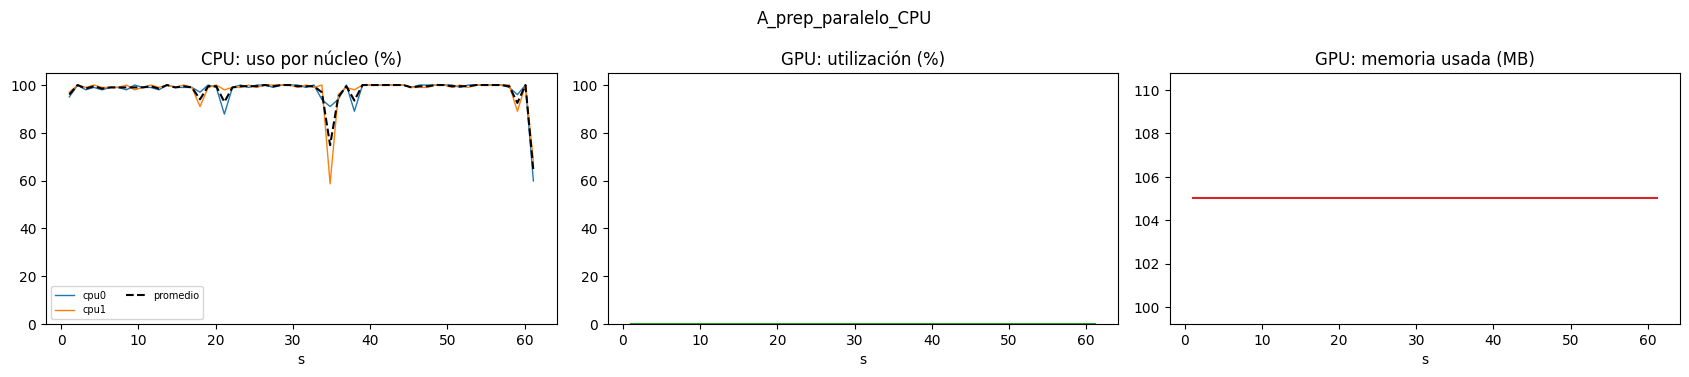

Preparación PARALELA (2 procesos): 20.28 ± 0.11 s
✓ Los arreglos de la versión paralela son idénticos a los de la secuencial.


In [10]:
# El worker vive en un módulo aparte (liviano: solo PIL+numpy) para poder usar el método "spawn".
Path("src").mkdir(exist_ok=True)
Path("src/cpu_prep.py").write_text("""
import numpy as np
from PIL import Image

def load_one(args):
    path, img_size = args
    with Image.open(path) as im:
        return np.asarray(im.convert("RGB").resize((img_size, img_size)), dtype=np.uint8)
""")
sys.path.insert(0, str(Path("src").resolve()))
import cpu_prep
import multiprocessing as mp

def prep_parallel(train_df, val_df, test_df, classes, n_workers=N_CPU, img_size=IMG_SIZE, chunksize=64):
    """Mismo resultado que prep_sequential, repartido entre n_workers procesos."""
    class_to_idx = {c: i for i, c in enumerate(classes)}
    out = []
    ctx = mp.get_context("spawn")
    with ctx.Pool(n_workers) as pool:                    # el arranque del pool SÍ cuenta en el tiempo medido
        for df in (train_df, val_df, test_df):
            imgs = pool.map(cpu_prep.load_one, [(p, img_size) for p in df["filepath"]], chunksize=chunksize)
            X = np.stack(imgs).astype(np.float32) / 255.0   # normalización vectorizada
            y = df["label"].map(class_to_idx).to_numpy(dtype=np.int64)
            out += [X, y]
    return tuple(out)

prep_par_times = []
with monitored("A_prep_paralelo_CPU"):
    for r in range(REPEATS):
        t0 = time.perf_counter()
        data_par = prep_parallel(train_df, val_df, test_df, classes)
        prep_par_times.append(time.perf_counter() - t0)
        print(f"  paralelo ({N_CPU} procesos), ejecución {r+1}/{REPEATS}: {prep_par_times[-1]:.2f} s")
print(f"Preparación PARALELA ({N_CPU} procesos): {np.mean(prep_par_times):.2f} ± {np.std(prep_par_times):.2f} s")

# Verificación de correctitud: la versión paralela produce EXACTAMENTE los mismos arreglos
for a, b, nm in zip(data_seq, data_par, ["Xtr", "ytr", "Xva", "yva", "Xte", "yte"]):
    assert a.dtype == b.dtype and np.array_equal(a, b), f"{nm} difiere"
print("✓ Los arreglos de la versión paralela son idénticos a los de la secuencial.")

In [11]:
# Escalamiento con el número de procesos (1 repetición por punto; para ver tendencia, no para el speedup oficial)
sweep = []
for w in sorted({1, 2, 4, 8, N_CPU, 2 * N_CPU}):
    t0 = time.perf_counter(); prep_parallel(train_df, val_df, test_df, classes, n_workers=w)
    sweep.append({"procesos": w, "tiempo_s": time.perf_counter() - t0})
sweep_df = pd.DataFrame(sweep); sweep_df["speedup_vs_secuencial"] = np.mean(prep_seq_times) / sweep_df["tiempo_s"]
sweep_df.to_csv(RESULTS_DIR / "prep_escalamiento.csv", index=False)
display(sweep_df)

,procesos,tiempo_s,speedup_vs_secuencial
0,1,23.924638,0.983094
1,2,20.219187,1.163260
2,4,19.281250,1.219846
3,8,21.552290,1.091307


### 6.2 Fase B/C — entrenamiento e inferencia en GPU (CUDA)

  GPU (CUDA, bs=32) [1/3] fit=37.7s  época(estable)=3.7s  infer=4.97s  acc_test=0.6591
  GPU (CUDA, bs=32) [2/3] fit=28.3s  época(estable)=3.7s  infer=1.70s  acc_test=0.6910
  GPU (CUDA, bs=32) [3/3] fit=28.5s  época(estable)=3.6s  infer=2.90s  acc_test=0.7094


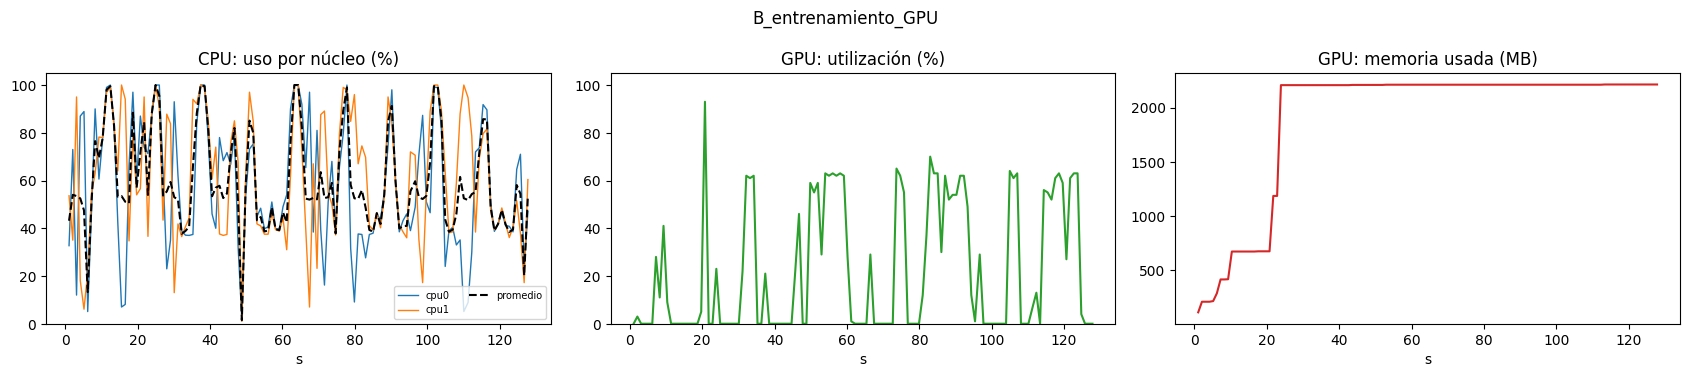

Sat Nov 14 06:05:40 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   74C    P0             30W /   70W |    2213MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [12]:
def build_cnn2_gpu(learning_rate=0.0005, mixed=False):
    """Misma arquitectura que build_cnn2. Si mixed=True usa float16 en capas (Tensor Cores) y deja la
    softmax final en float32 para estabilidad numérica."""
    keras.mixed_precision.set_global_policy("mixed_float16" if mixed else "float32")
    model = keras.Sequential([
        layers.Input(shape=(64, 64, 3)),
        layers.Conv2D(32, 3, activation="relu"), layers.BatchNormalization(), layers.MaxPooling2D(2),
        layers.Conv2D(64, 3, activation="relu"), layers.BatchNormalization(), layers.MaxPooling2D(2),
        layers.Conv2D(128, 3, activation="relu"), layers.BatchNormalization(), layers.MaxPooling2D(2),
        layers.Flatten(),
        layers.Dense(256, activation="relu"), layers.Dropout(0.4),
        layers.Dense(128, activation="relu"), layers.Dropout(0.3),
        layers.Dense(29, activation="softmax", dtype="float32"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    keras.mixed_precision.set_global_policy("float32")
    return model

if GPU_DEVICE:
    # Los datos de entrada son los que produjo la fase A PARALELA (ya verificados idénticos a los secuenciales)
    with monitored("B_entrenamiento_GPU"):
        benchmark("GPU (CUDA, bs=32)", GPU_DEVICE, lambda: build_cnn2_gpu(LEARNING_RATE), data_par, BATCH_SIZE,
                  snapshot_path=RESULTS_DIR / "nvidia_smi_durante_entrenamiento_bs32.txt")
    print(Path(RESULTS_DIR / "nvidia_smi_durante_entrenamiento_bs32.txt").read_text())
else:
    print("Sin GPU: se omite.")

  GPU optimizado (CUDA, bs=128, fp16) [1/3] fit=31.6s  época(estable)=1.8s  infer=3.29s  acc_test=0.2059
  GPU optimizado (CUDA, bs=128, fp16) [2/3] fit=24.2s  época(estable)=1.7s  infer=2.10s  acc_test=0.2059
  GPU optimizado (CUDA, bs=128, fp16) [3/3] fit=24.5s  época(estable)=1.8s  infer=2.07s  acc_test=0.2059


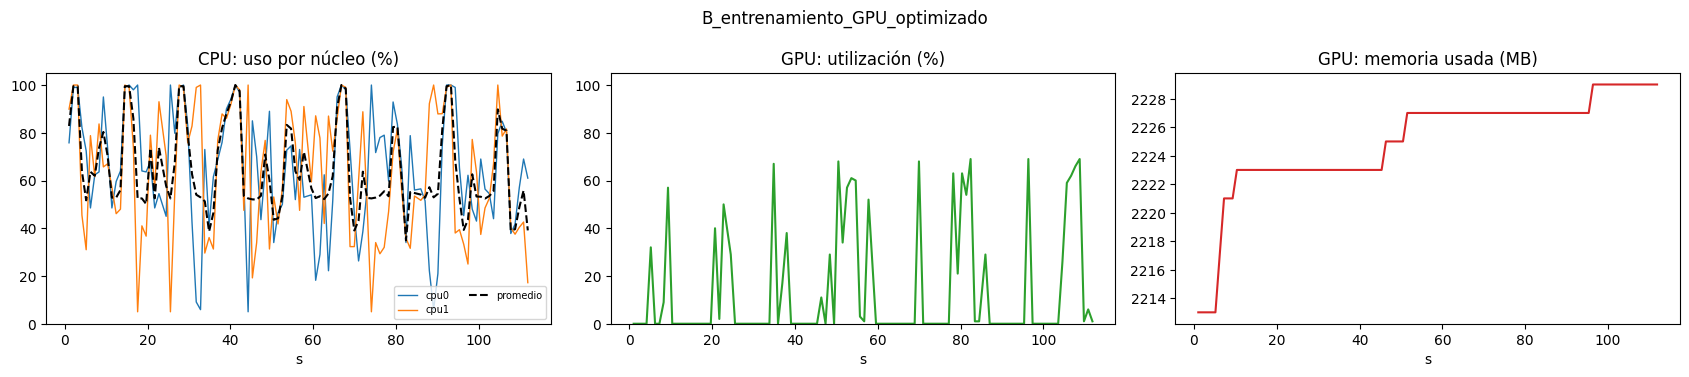

Sat Nov 14 06:07:49 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   74C    P0             29W /   70W |    2229MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [13]:
if GPU_DEVICE:
    with monitored("B_entrenamiento_GPU_optimizado"):
        benchmark("GPU optimizado (CUDA, bs=128, fp16)", GPU_DEVICE,
                  lambda: build_cnn2_gpu(LEARNING_RATE, mixed=True), data_par, 128,
                  snapshot_path=RESULTS_DIR / "nvidia_smi_durante_entrenamiento_bs128_fp16.txt")
    print(Path(RESULTS_DIR / "nvidia_smi_durante_entrenamiento_bs128_fp16.txt").read_text())

### 6.3 Costo de la transferencia CPU ↔ GPU
`fit()` ya incluye las transferencias por batch dentro de su tiempo. Aquí se aíslan para cuantificarlas: copiar todo el conjunto de entrenamiento (`float32`, ≈ 0.7 GB) host→device y traer de vuelta las predicciones.

In [14]:
if GPU_DEVICE:
    xh = tf.constant(Xtr)                                  # en memoria del host
    h2d = []
    for _ in range(REPEATS + 1):
        t0 = time.perf_counter()
        with tf.device(GPU_DEVICE):
            xg = tf.identity(xh)
            _ = tf.reduce_sum(xg[:1]).numpy()              # fuerza sincronización
        h2d.append(time.perf_counter() - t0)
    h2d = h2d[1:]                                          # descarta la primera (inicialización del contexto)
    gb = Xtr.nbytes / 1e9
    print(f"Host→GPU de {gb:.2f} GB: {np.mean(h2d):.3f} ± {np.std(h2d):.3f} s  ({gb/np.mean(h2d):.1f} GB/s)")
    T_H2D = float(np.mean(h2d)); del xg
else:
    T_H2D = np.nan

Host→GPU de 0.70 GB: 0.001 ± 0.000 s  (605.1 GB/s)


> ⚠️ **Nota sobre la celda anterior (6.3):** la cifra de 605 GB/s **no es válida** (el PCIe de una T4 ronda 12 GB/s): `tf.identity` sobre un tensor ya residente no realizó la copia. El costo real de transferencia está incluido en el tiempo de `fit()` y se mide correctamente en `proyecto3_complemento.ipynb` (parte B), cuyos resultados reemplazan a este.

### 6.4 Kernel CUDA propio con Numba (`Dense 4608→256 + ReLU`)
Mapeo explícito: **hilo (tx,ty)** calcula **una** neurona de salida para **una** muestra; **bloque** de 16×16 hilos = un *tile* de 16 muestras × 16 neuronas; **grid** de `⌈256/16⌉ × ⌈M/16⌉` bloques cubre toda la matriz de salida. La versión *tiled* carga fragmentos de `X` y `W` en memoria compartida para reutilizarlos 16 veces y reducir lecturas de memoria global.

In [17]:
if GPU_DEVICE:
    from numba import cuda, float32
    import numba

    TPB = 16

    @cuda.jit
    def dense_relu_naive(X, W, b, Y):
        col = cuda.blockIdx.x * cuda.blockDim.x + cuda.threadIdx.x      # neurona de salida
        row = cuda.blockIdx.y * cuda.blockDim.y + cuda.threadIdx.y      # muestra del batch
        if row < Y.shape[0] and col < Y.shape[1]:
            acc = 0.0
            for k in range(X.shape[1]):
                acc += X[row, k] * W[k, col]
            acc += b[col]
            Y[row, col] = acc if acc > 0.0 else 0.0

    @cuda.jit
    def dense_relu_tiled(X, W, b, Y):
        sX = cuda.shared.array((TPB, TPB), float32)
        sW = cuda.shared.array((TPB, TPB), float32)
        tx, ty = cuda.threadIdx.x, cuda.threadIdx.y
        col = cuda.blockIdx.x * TPB + tx
        row = cuda.blockIdx.y * TPB + ty
        M, K, N = Y.shape[0], X.shape[1], Y.shape[1]
        acc = 0.0
        for t in range((K + TPB - 1) // TPB):
            k0 = t * TPB
            sX[ty, tx] = X[row, k0 + tx] if (row < M and k0 + tx < K) else 0.0
            sW[ty, tx] = W[k0 + ty, col] if (k0 + ty < K and col < N) else 0.0
            cuda.syncthreads()
            for j in range(TPB):
                acc += sX[ty, j] * sW[j, tx]
            cuda.syncthreads()
        if row < M and col < N:
            v = acc + b[col]
            Y[row, col] = v if v > 0.0 else 0.0

    M, K, N = 3045, 4608, 256            # test set × (6·6·128) → 256, como en la CNN 2
    rng = np.random.default_rng(SEED)
    Xh = rng.standard_normal((M, K), dtype=np.float32)
    Wh = (rng.standard_normal((K, N), dtype=np.float32) * 0.02).astype(np.float32)
    bh = rng.standard_normal(N, dtype=np.float32) * 0.1
    ref = np.maximum(Xh @ Wh + bh, 0)

    t0 = time.perf_counter()
    try:
        dX, dW, db = cuda.to_device(Xh), cuda.to_device(Wh), cuda.to_device(bh)
        dY = cuda.device_array((M, N), dtype=np.float32); cuda.synchronize()
        t_copy = time.perf_counter() - t0
        numba_available = True
    except Exception as e:
        print(f"⚠️ No se pudo inicializar CUDA a través de Numba: {e}")
        numba_available = False
        t_copy = np.nan

    block = (TPB, TPB)
    grid  = ((N + TPB - 1) // TPB, (M + TPB - 1) // TPB)     # (x=neuronas, y=muestras)
    print(f"block={block} ({TPB*TPB} hilos/bloque), grid={grid} → {grid[0]*grid[1]} bloques, {grid[0]*grid[1]*TPB*TPB:,} hilos")

    def bench_kernel(kern, reps=20):
        kern[grid, block](dX, dW, db, dY); cuda.synchronize()          # compila + calienta
        t0 = time.perf_counter()
        for _ in range(reps): kern[grid, block](dX, dW, db, dY)
        cuda.synchronize(); return (time.perf_counter() - t0) / reps

    res_k = {}
    if numba_available:
        for name, kern in [("Numba naive", dense_relu_naive), ("Numba tiled (shared mem)", dense_relu_tiled)]:
            try:
                res_k[name] = bench_kernel(kern)
                ok = np.allclose(dY.copy_to_host(), ref, atol=1e-2, rtol=1e-3)
                print(f"{name:28s}: {res_k[name]*1e3:8.3f} ms   correcto vs NumPy: {ok}")
            except Exception as e:
                print(f"⚠️ Fallo de nvJitLink al compilar {name}: {e}")
                res_k[name] = np.nan
    else:
        res_k["Numba naive"] = np.nan
        res_k["Numba tiled (shared mem)"] = np.nan

    with tf.device(GPU_DEVICE):
        xt, wt, bt = tf.constant(Xh), tf.constant(Wh), tf.constant(bh)
        f = lambda: tf.nn.relu(tf.matmul(xt, wt) + bt)
        f().numpy()
        t0 = time.perf_counter()
        for _ in range(20): y_ = f()
        y_.numpy(); res_k["tf.matmul (cuBLAS)"] = (time.perf_counter() - t0) / 20
    print(f"{'tf.matmul (cuBLAS)':28s}: {res_k['tf.matmul (cuBLAS)']*1e3:8.3f} ms")

    t0 = time.perf_counter(); _ = np.maximum(Xh @ Wh + bh, 0); res_k["NumPy (CPU)"] = time.perf_counter() - t0
    print(f"{'NumPy (CPU)':28s}: {res_k['NumPy (CPU)']*1e3:8.3f} ms")
    if not np.isnan(t_copy):
        print(f"(copia host→device de las matrices: {t_copy*1e3:.1f} ms)")

    pd.DataFrame({"implementacion": list(res_k), "ms": [v*1e3 for v in res_k.values()]}).to_csv(RESULTS_DIR / "kernel_numba.csv", index=False)

block=(16, 16) (256 hilos/bloque), grid=(16, 191) → 3056 bloques, 782,336 hilos
⚠️ Fallo de nvJitLink al compilar Numba naive: ERROR_INTERNAL (6)
nvJitLink error log: ERROR 4 in nvvmAddNVVMContainerToProgram, may need newer version of nvJitLink library
 
⚠️ Fallo de nvJitLink al compilar Numba tiled (shared mem): ERROR_INTERNAL (6)
nvJitLink error log: ERROR 4 in nvvmAddNVVMContainerToProgram, may need newer version of nvJitLink library
 
tf.matmul (cuBLAS)          :    2.765 ms
NumPy (CPU)                 :   70.676 ms
(copia host→device de las matrices: 45.8 ms)


> ⚠️ **Nota sobre la celda anterior (6.4):** Numba falló al compilar (`nvJitLink … may need newer version of nvJitLink library`: incompatibilidad entre el nvJitLink de CUDA 12.5 que trae TensorFlow y el NVVM de Numba); por eso `Numba naive` y `Numba tiled` quedaron en `NaN`. Los kernels se repiten en `proyecto3_complemento.ipynb` (parte A) actualizando `nvidia-nvjitlink-cu12` antes de importar Numba, y también en CUDA C vía CuPy/NVRTC.

## 7. Análisis y conclusiones (Paso 6)
### 7.1 Tabla comparativa de tiempos y speedup por fase

In [18]:
runs_df = pd.DataFrame(runs); runs_df.to_csv(RESULTS_DIR / "benchmark_ejecuciones.csv", index=False)

summary = runs_df.groupby("config", sort=False).agg(
    fit_s=("train_s", "mean"), fit_std=("train_s", "std"),
    epoca_estable_s=("epoch_steady_s", "mean"), primera_epoca_s=("epoch_first_s", "mean"),
    inferencia_s=("infer_s", "mean"), inferencia_std=("infer_s", "std"),
    acc_test=("test_acc", "mean")).reset_index()
summary.to_csv(RESULTS_DIR / "benchmark_resumen.csv", index=False)
display(summary.round(3))

prep_seq, prep_par = float(np.mean(prep_seq_times)), float(np.mean(prep_par_times))
cpu = summary[summary.config.str.startswith("CPU")].iloc[0]

rows = [{"Fase": "A. Preparación de imágenes (CPU 1 proceso → CPU %d procesos)" % N_CPU,
         "Secuencial (s)": prep_seq, "Paralelo (s)": prep_par, "Speedup": prep_seq / prep_par,
         "Eficiencia": prep_seq / prep_par / N_CPU}]
for _, g in summary[summary.config.str.startswith("GPU")].iterrows():
    tag = g.config
    rows += [
      {"Fase": f"B. Entrenamiento ({EPOCHS_BENCH} épocas) — {tag}", "Secuencial (s)": cpu.fit_s, "Paralelo (s)": g.fit_s, "Speedup": cpu.fit_s / g.fit_s},
      {"Fase": f"B'. Época en régimen estable — {tag}", "Secuencial (s)": cpu.epoca_estable_s, "Paralelo (s)": g.epoca_estable_s, "Speedup": cpu.epoca_estable_s / g.epoca_estable_s},
      {"Fase": f"C. Inferencia sobre test — {tag}", "Secuencial (s)": cpu.inferencia_s, "Paralelo (s)": g.inferencia_s, "Speedup": cpu.inferencia_s / g.inferencia_s},
      {"Fase": f"Extremo a extremo (A+B+C) — {tag}", "Secuencial (s)": prep_seq + cpu.fit_s + cpu.inferencia_s,
       "Paralelo (s)": prep_par + g.fit_s + g.inferencia_s,
       "Speedup": (prep_seq + cpu.fit_s + cpu.inferencia_s) / (prep_par + g.fit_s + g.inferencia_s)},
    ]
speed = pd.DataFrame(rows); speed.to_csv(RESULTS_DIR / "speedups.csv", index=False)
display(speed.round(3))
if GPU_DEVICE:
    print(f"Transferencia host→GPU del set de entrenamiento: {T_H2D:.3f} s  "
          f"({100*T_H2D/summary[summary.config.str.startswith('GPU (CUDA, bs=32')].fit_s.iloc[0]:.1f} % del fit en GPU bs=32)")

,config,fit_s,fit_std,epoca_estable_s,primera_epoca_s,inferencia_s,inferencia_std,acc_test
0,"CPU (secuencial, bs=32)",692.195,38.243,175.849,163.739,8.229,1.948,0.718
1,"GPU (CUDA, bs=32)",31.504,5.380,3.695,18.870,3.189,1.655,0.686
2,"GPU optimizado (CUDA, bs=128, fp16)",26.787,4.212,1.746,19.970,2.486,0.694,0.206


,Fase,Secuencial (s),Paralelo (s),Speedup,Eficiencia
0,A. Preparación de imágenes (CPU 1 proceso → CP...,23.520,20.277,1.160,0.58
1,"B. Entrenamiento (4 épocas) — GPU (CUDA, bs=32)",692.195,31.504,21.972,NaN
2,"B'. Época en régimen estable — GPU (CUDA, bs=32)",175.849,3.695,47.591,NaN
3,"C. Inferencia sobre test — GPU (CUDA, bs=32)",8.229,3.189,2.580,NaN
4,"Extremo a extremo (A+B+C) — GPU (CUDA, bs=32)",723.945,54.970,13.170,NaN
5,B. Entrenamiento (4 épocas) — GPU optimizado (...,692.195,26.787,25.841,NaN
6,B'. Época en régimen estable — GPU optimizado ...,175.849,1.746,100.724,NaN
7,C. Inferencia sobre test — GPU optimizado (CUD...,8.229,2.486,3.311,NaN
8,Extremo a extremo (A+B+C) — GPU optimizado (CU...,723.945,49.550,14.610,NaN


Transferencia host→GPU del set de entrenamiento: 0.001 s  (0.0 % del fit en GPU bs=32)


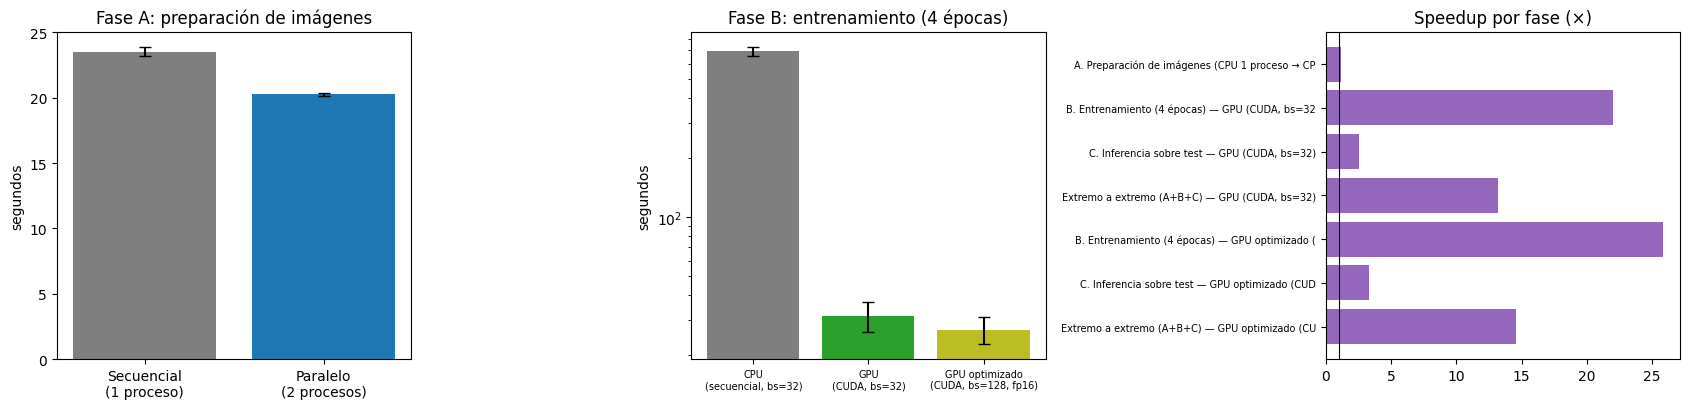

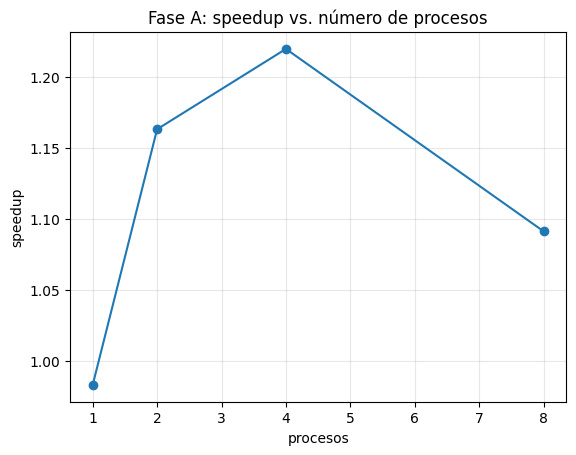

In [19]:
# Gráficas comparativas
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ax[0].bar(["Secuencial\n(1 proceso)", f"Paralelo\n({N_CPU} procesos)"], [prep_seq, prep_par],
          yerr=[np.std(prep_seq_times), np.std(prep_par_times)], color=["tab:gray", "tab:blue"], capsize=4)
ax[0].set(title="Fase A: preparación de imágenes", ylabel="segundos")
cfgs = list(summary.config)
ax[1].bar(range(len(cfgs)), summary.fit_s, yerr=summary.fit_std.fillna(0), capsize=4,
          color=["tab:gray"] + ["tab:green", "tab:olive"][:len(cfgs)-1])
ax[1].set_xticks(range(len(cfgs))); ax[1].set_xticklabels([c.replace(" (", "\n(") for c in cfgs], fontsize=7)
ax[1].set(title=f"Fase B: entrenamiento ({EPOCHS_BENCH} épocas)", ylabel="segundos")
ax[1].set_yscale("log")
sp = speed[~speed.Fase.str.startswith("B'")]
ax[2].barh(range(len(sp)), sp.Speedup, color="tab:purple"); ax[2].axvline(1, color="k", lw=.8)
ax[2].set_yticks(range(len(sp))); ax[2].set_yticklabels([f[:46] for f in sp.Fase], fontsize=7)
ax[2].set(title="Speedup por fase (×)"); ax[2].invert_yaxis()
plt.tight_layout(); plt.savefig(RESULTS_DIR / "comparacion_tiempos_speedup.png", dpi=130); plt.show()

sweep_df.plot(x="procesos", y="speedup_vs_secuencial", marker="o", legend=False, title="Fase A: speedup vs. número de procesos")
plt.ylabel("speedup"); plt.grid(alpha=.3); plt.savefig(RESULTS_DIR / "prep_escalamiento.png", dpi=130); plt.show()

### 7.2 Equivalencia de resultados (el GPU no cambia el modelo)

In [20]:
display(runs_df.groupby("config", sort=False)["test_acc"].agg(["mean", "std", "min", "max"]).round(4))
print("Las diferencias pequeñas se deben a no determinismo de los kernels de GPU y al orden de operaciones en punto flotante,"
      " no a un modelo distinto. El config con batch 128 + fp16 SÍ cambia la dinámica de entrenamiento (otro batch size).")

,mean,std,min,max
config,,,,
"CPU (secuencial, bs=32)",0.7179,0.0000,0.7179,0.7179
"GPU (CUDA, bs=32)",0.6865,0.0254,0.6591,0.7094
"GPU optimizado (CUDA, bs=128, fp16)",0.2059,0.0000,0.2059,0.2059


Las diferencias pequeñas se deben a no determinismo de los kernels de GPU y al orden de operaciones en punto flotante, no a un modelo distinto. El config con batch 128 + fp16 SÍ cambia la dinámica de entrenamiento (otro batch size).


### 7.3 Exportar tablas para el informe y empaquetar resultados

In [21]:
md_out = []
md_out.append(f"## Entorno\n\n```\n{hw[:1500]}\n```\n")
md_out.append(f"- Núcleos CPU: {N_CPU}  |  TensorFlow {tf.__version__}  |  Épocas de benchmark: {EPOCHS_BENCH}  |  Repeticiones: {REPEATS}\n")
md_out.append("\n## Tiempos de preparación (s)\n\n| Ejecución | Secuencial | Paralelo |\n|---|---|---|\n" +
              "\n".join(f"| {i+1} | {a:.2f} | {b:.2f} |" for i, (a, b) in enumerate(zip(prep_seq_times, prep_par_times))) +
              f"\n| **Promedio ± σ** | {np.mean(prep_seq_times):.2f} ± {np.std(prep_seq_times):.2f} | {np.mean(prep_par_times):.2f} ± {np.std(prep_par_times):.2f} |\n")
md_out.append("\n## Entrenamiento / inferencia (promedio de las ejecuciones)\n\n" + summary.round(3).to_markdown(index=False) + "\n")
md_out.append("\n## Speedup por fase\n\n" + speed.round(3).to_markdown(index=False) + "\n")
md_out.append("\n## Escalamiento de la fase A\n\n" + sweep_df.round(3).to_markdown(index=False) + "\n")
(RESULTS_DIR / "informe_tablas.md").write_text("\n".join(md_out))

zip_path = "resultados_proyecto3.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in RESULTS_DIR.rglob("*"):
        if p.is_file(): z.write(p)
print("Listo →", zip_path)
try:
    from google.colab import files; files.download(zip_path)
except Exception:
    pass

Listo → resultados_proyecto3.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 7.4 Discusión técnica
La discusión completa, con los números medidos, está en `docs/informe_rendimiento.pdf` (sección 6). Resumen:

* **CPU para archivos, GPU para la red.** Decodificar JPEG (Huffman, ramas, acceso a disco) no encaja en el modelo SIMT y es independiente por imagen → procesos en CPU. Convoluciones/GEMM/retropropagación son regulares y densas → GPU (cuDNN/cuBLAS). Se preprocesa una sola vez y solo se mueven tensores listos.
* **Efecto de CUDA.** Época estable 175.8 s → 3.7 s (47.6×); 4 épocas 692 s → 31.5 s (22.0×); extremo a extremo 724 s → 55 s (13.2×). La 1.ª época en GPU cuesta ≈ 19 s (inicialización de cuDNN y trazado del grafo), costo fijo que se amortiza con más épocas.
* **Preparación en CPU:** solo 1.16× con 2 procesos porque las 2 vCPU de Colab son 1 núcleo físico con 2 hilos (el escalamiento se estanca en ≈ 1.2×).
* **Límites:** Amdahl (tras acelerar el entrenamiento, la preparación pasa de 3 % a 37 % del tiempo), GPU subutilizado (media 23 %: batch 32 y red pequeña; con bs=128+fp16 la época baja a 1.75 s pero la utilización también baja a 14 %), costos fijos de inicialización/lanzamiento (la inferencia solo mejora 2.6×), transferencias PCIe y compatibilidad de versiones CUDA (falló Numba).
* **Precaución:** con 4 épocas fijas la exactitud (≈ 69-72 %) no representa la calidad final; el entrenamiento hasta convergencia está en `proyecto3_complemento.ipynb` (parte C).
* **Librerías que usan el GPU:** CUDA runtime/driver, cuDNN, cuBLAS, TensorFlow/Keras (`tf.device`, `mixed_precision`), Numba/CuPy (kernels propios), `nvidia-smi`.